# Regression model comparison

**Dataset used**: 'All time premier league player statistics'(data until 2020 season),

Source: Kaggle

[This is a learning project to compare how different regression methods behave on the same data. The feature set was chosen for simplicity.]
The objective here is to find out which regression analysis works best for the selected dataset. cross validation, a standard statistical testing method is performed for the same. 5 different types of regression models are applied. those are:

1. Linear Regression
2. Ridge Regression
3. Lasso Regression
4. Random Forest Regression
5. Gradient boosting Regression

The aim of each regression model is
to Predict a football player's goals based on their position, age, and shots on target.(or try and see how much variables such as age, position and shots on target affect the no. of goals being produced in the premier league)

So, here the **dependent variable** is : GOAL

and the **independent variables** are : AGE, POSITION, AND SHOTS ON TARGET

(EDA and Data visualisation has been done for better understanding the data)

In [1]:
import os
import zipfile
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
uploaded = files.upload()   # upload dataset - 2020-09-24.csv

fname = list(uploaded.keys())[0]   # uses the file you just uploaded, whatever Colab renamed it
data = pd.read_csv(fname)
print(data.shape)
data.head()

# Import all the required libraries and modules for our model building
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor

regressors = {
    'Baseline (mean)': DummyRegressor(strategy='mean'),
    'LinearRegression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0, random_state=42),
    'Lasso': Lasso(alpha=0.1, random_state=42, max_iter=5000),
    'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42),
    'GradientBoosting': GradientBoostingRegressor(n_estimators=100, random_state=42)
}
print('Libraries imported and data loaded successfully.')

features = ['Position', 'Age', 'Shots on target']
target = 'Goals'

X = data[features]
y = data[target]

# One-hot encoding
X_encoded = pd.get_dummies(X, columns=['Position'], drop_first=True)

# Handling missing data
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X_encoded)

X_reg = X_imputed
y_reg = y.values

kf = KFold(n_splits=5, shuffle=True, random_state=42)
mse_scores = {name: [] for name in regressors}

print("Starting 5-fold cross-validation")
for fold_idx, (train_idx, test_idx) in enumerate(kf.split(X_reg)):
    Xtr, Xte = X_reg[train_idx], X_reg[test_idx]
    ytr, yte = y_reg[train_idx], y_reg[test_idx]

    scaler = StandardScaler().fit(Xtr)
    Xtr_s = scaler.transform(Xtr)
    Xte_s = scaler.transform(Xte)

    for name, model in regressors.items():
        if name in ('LinearRegression', 'Ridge', 'Lasso'):
            model.fit(Xtr_s, ytr)
            preds = model.predict(Xte_s)
        else:
            model.fit(Xtr, ytr)
            preds = model.predict(Xte)

        mse = mean_squared_error(yte, preds)
        mse_scores[name].append(mse)

mse_df = pd.DataFrame(mse_scores)
mse_df.index = [f'Fold_{i+1}' for i in range(mse_df.shape[0])]

print('\n--- Mean Squared Error (MSE) Results (Cross-Validation) ---')
display(mse_df)

print('\n--- Model Mean MSEs (lower is better) ---')
display(mse_df.mean().sort_values())

print("\nTraining models on the full dataset for coefficient/importance analysis...")
X_full = X_imputed
y_full = y.values
scaler_full = StandardScaler().fit(X_full)
X_full_s = scaler_full.transform(X_full)

trained_regressors = {}
for name, model in regressors.items():
    if name in ('LinearRegression', 'Ridge', 'Lasso'):
        model.fit(X_full_s, y_full)
    else:
        model.fit(X_reg, y_reg)
    trained_regressors[name] = model

print("Training complete.")

Saving dataset - 2020-09-24.csv to dataset - 2020-09-24.csv
(571, 59)
Libraries imported and data loaded successfully.
Starting 5-fold cross-validation

--- Mean Squared Error (MSE) Results (Cross-Validation) ---


,Baseline (mean),LinearRegression,Ridge,Lasso,RandomForest,GradientBoosting
Fold_1,153.402813,17.798157,17.758853,17.635547,16.035346,13.143552
Fold_2,136.641215,20.522269,20.356395,20.056720,17.459942,20.018841
Fold_3,452.135440,28.363273,28.479894,29.033593,24.891132,28.456950
Fold_4,272.557106,18.661609,18.638779,18.749689,23.483660,20.940769
Fold_5,402.499936,32.175599,32.321565,32.490384,54.035404,32.698526



--- Model Mean MSEs (lower is better) ---


,0
GradientBoosting,23.051727
LinearRegression,23.504181
Ridge,23.511097
Lasso,23.593187
RandomForest,27.181097
Baseline (mean),283.447302



Training models on the full dataset for coefficient/importance analysis...
Training complete.


Goals                0
Age                  1
Shots on target    262
Position             0
dtype: int64


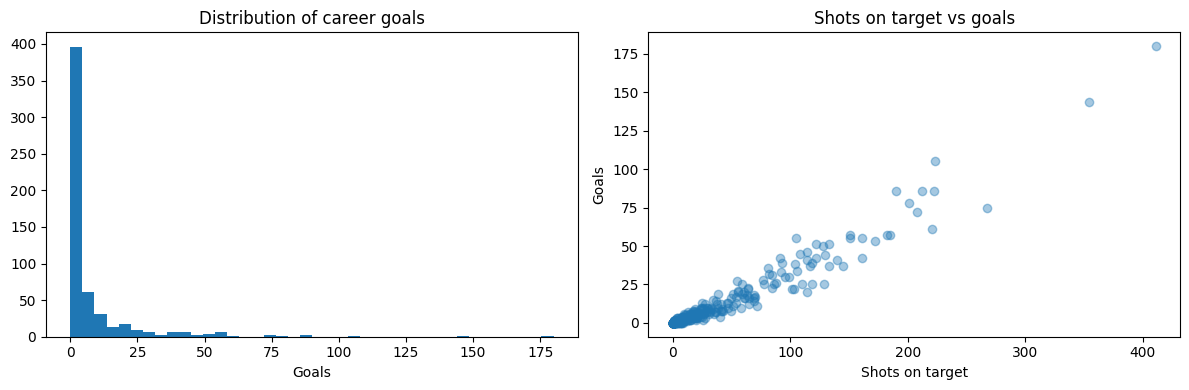

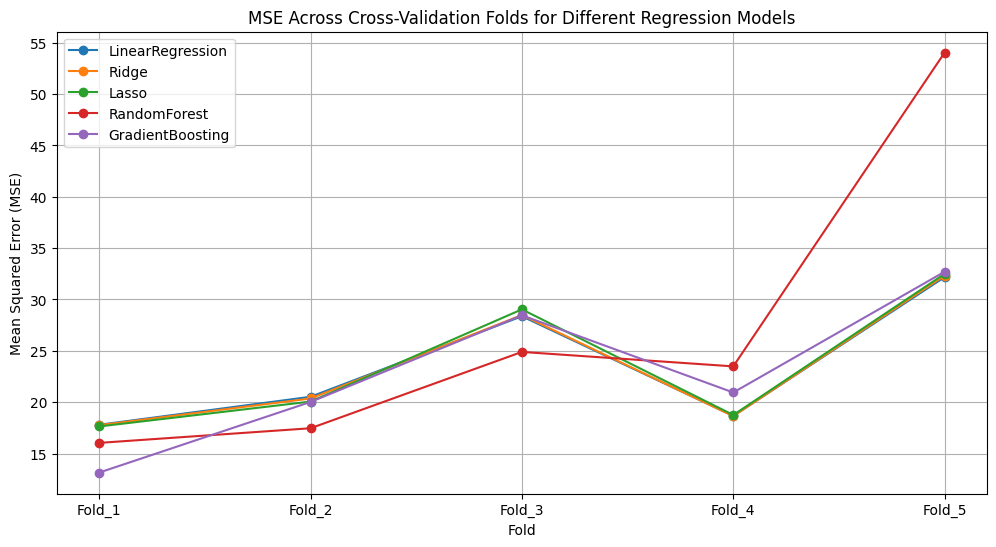

In [2]:
print(data[['Goals', 'Age', 'Shots on target', 'Position']].isna().sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(data['Goals'].dropna(), bins=40)
ax[0].set_title('Distribution of career goals'); ax[0].set_xlabel('Goals')
ax[1].scatter(data['Shots on target'], data['Goals'], alpha=0.4)
ax[1].set_title('Shots on target vs goals')
ax[1].set_xlabel('Shots on target'); ax[1].set_ylabel('Goals')
plt.tight_layout(); plt.show()

# Plot the MSE results across folds
plt.figure(figsize=(12, 6))
for name, scores in mse_scores.items():
    if name == 'Baseline (mean)':
        continue
    plt.plot(mse_df.index, scores, marker='o', linestyle='-', label=name)

plt.xlabel('Fold')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MSE Across Cross-Validation Folds for Different Regression Models')
plt.legend()
plt.grid(True)
plt.show()

In [3]:
mean_mse = mse_df.mean()
summary = pd.DataFrame({
    'MSE': mean_mse,
    'RMSE': np.sqrt(mean_mse),
    'R2 vs baseline': 1 - mean_mse / mean_mse['Baseline (mean)']
}).sort_values('MSE')
display(summary.round(3))

,MSE,RMSE,R2 vs baseline
GradientBoosting,23.052,4.801,0.919
LinearRegression,23.504,4.848,0.917
Ridge,23.511,4.849,0.917
Lasso,23.593,4.857,0.917
RandomForest,27.181,5.214,0.904
Baseline (mean),283.447,16.836,0.000


Now that we are done with the cross validation, Lets try and make sense of the results:
We have in the first table the MSEs (Mean squared error) for each regression model in each fold, to compare the mean of MSEs in each fold is taken. and in the second table we have 'Model mean MSEs'

**Mean squared error** is the average of the squared differences between the predicted values (y^) and the actual values (y):

Interpretation: MSE penalizes large errors more heavily due to the squaring operation. The lower the MSE, the better the model's performance.

In that case we take the Regression model with the least MSE, ie, Gradient Boosting regression.

In our visualisation where we plots MSE across folds, we can see that Gradient boosting regression had the lowest MSE on average, though not in every fold. Linear, Ridge and Lasso had very similar MSEs across folds and Random forest had the highest mean MSE among the five models and also showed the most variability with a noticeably high MSE in the fifth fold.

well then, that seals it.

But, wait!

Now, we do have results implying gradient boosting is the best since it has the lowest average error. But although Gradient Boosting has the lowest mean MSE, the gap to the linear models is small. Mean error alone can’t tell us whether that gap is real. So, we go ahead and do a paired t-test on the fold wise MSE’s to determine if the model’s superiority is statistically significant or legitimate in the stats world.

we use a Paired t- test to determine if a model's superiority is statistically significant. Because the MSE measurements for two different models are paired across the same k cross validation folds.

As usual we have our Null and Alternate hypothesises:

**Null Hypothesis** (H₀): The mean difference in MSE between Model A and Model B is zero ( μA−μB=0 ).

**Alternative Hypothesis** (Hₐ): The mean difference in MSE is not zero ( μA−μB≠0 ).

In [4]:
reg_names = [n for n in mse_scores.keys() if n != 'Baseline (mean)']
ttest_results = []

print("Performing paired t-tests between regression models")

for i in range(len(reg_names)):
    for j in range(i+1, len(reg_names)):
        a = np.array(mse_scores[reg_names[i]])
        b = np.array(mse_scores[reg_names[j]])

        tstat, pval = stats.ttest_rel(a, b)
        ttest_results.append({'model_a': reg_names[i], 'model_b': reg_names[j], 't_stat': tstat, 'p_value': pval, 'mean_diff (a-b)': a.mean()-b.mean()})


tt_df = pd.DataFrame(ttest_results).sort_values('p_value')

print('Regression Paired t-test Results (sorted by p-value)')
display(tt_df)

Performing paired t-tests between regression models
Regression Paired t-test Results (sorted by p-value)


,model_a,model_b,t_stat,p_value,mean_diff (a-b)
9,RandomForest,GradientBoosting,0.918664,0.410255,4.129370
5,Ridge,RandomForest,-0.772111,0.483133,-3.670000
2,LinearRegression,RandomForest,-0.768324,0.485144,-3.676916
7,Lasso,RandomForest,-0.757496,0.490926,-3.587910
4,Ridge,Lasso,-0.567350,0.600803,-0.082089
8,Lasso,GradientBoosting,0.495417,0.646288,0.541459
1,LinearRegression,Lasso,-0.456663,0.671611,-0.089005
6,Ridge,GradientBoosting,0.404440,0.706582,0.459370
3,LinearRegression,GradientBoosting,0.394020,0.713669,0.452454
0,LinearRegression,Ridge,-0.122017,0.908770,-0.006916


What do the results tell us?

 A commonly used threshold for statistical significance is a p-value of 0.05. If a p-value is less than 0.05, we would typically consider the difference statistically significant, meaning it's unlikely to have occurred by random chance.

 Here, all the p values are quite high and greater than 0.05, so we fail to reject the null hypothesis which states that The mean difference in MSE between Model A and Model B is zero, in other words,

 **There is no statistically significant evidence, based on this 5-fold cross-validation, to conclude that the mean MSE of any one model is truly different from the mean MSE of any other model!**

 With only 5 folds the test has low power, and 10
 pairwise comparisons were run without correction, so these p-values are indicative only.

 Anywho, let's move on to bagging and boosting. Now bagging  fits multiple regressions on different bootstrap samples and averages them. We have already done random forest regression, a special case of bagging using decision trees.
 While bagging aggregates independent models, boosting builds models sequentially.
each new model tries to explain what the previous ones missed, almost like the gradient boosting regression we are familiar with.


In [5]:
from sklearn.ensemble import BaggingRegressor
from sklearn.linear_model import LinearRegression
import numpy as np

bagging_model = BaggingRegressor(
    estimator=LinearRegression(),
    n_estimators=50,
    bootstrap=True,
    random_state=0
)

bagging_model.fit(X_reg, y_reg)

print("Bagging Regressor trained on the dataset.")



Bagging Regressor trained on the dataset.


Bagging out-of-fold RMSE: 4.846


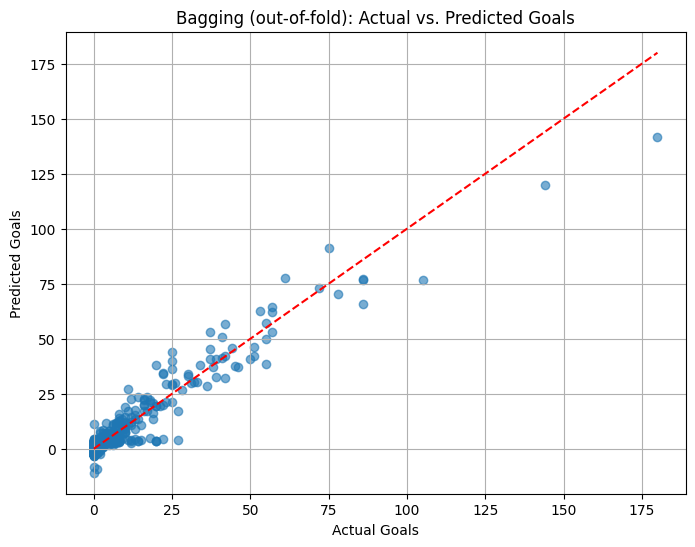

In [6]:


from sklearn.model_selection import cross_val_predict
bagging_predictions = cross_val_predict(bagging_model, X_reg, y_reg, cv=kf)
print('Bagging out-of-fold RMSE:', np.sqrt(mean_squared_error(y_reg, bagging_predictions)).round(3))
# we Create a scatter plot of actual vs. predicted goals to better understand our results.
plt.figure(figsize=(8, 6))
plt.scatter(y_reg, bagging_predictions, alpha=0.6)
plt.xlabel("Actual Goals")
plt.ylabel("Predicted Goals")
plt.title("Bagging (out-of-fold): Actual vs. Predicted Goals")
plt.grid(True)

max_goals = max(y_reg.max(), bagging_predictions.max())
plt.plot([0, max_goals], [0, max_goals], color='red', linestyle='--')

plt.show()

The red diagnol line is for perfect predictions.So the blue dots close to this line are good predictions and dots far above r below are prediction errors. From our scatter plot Our bagging regressor seems to generalise fairly okay although there are some deviations.

Similarly, we visualise a scatter plot for Bosting also.

In [7]:
from sklearn.ensemble import GradientBoostingRegressor

boost_model = GradientBoostingRegressor(
    n_estimators=100,
    random_state=42 # Using the same random state as before
)

boost_model.fit(X_reg, y_reg)

print("Gradient Boosting Regressor trained on the dataset.")



Gradient Boosting Regressor trained on the dataset.


Boosting out-of-fold RMSE: 4.799


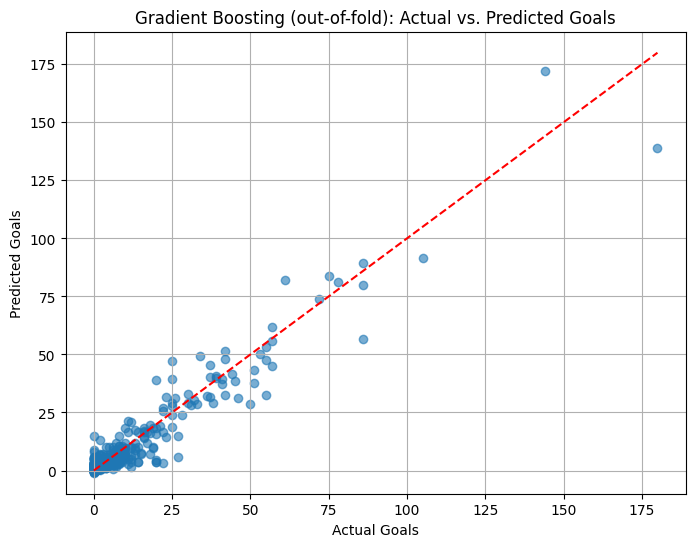

In [8]:

from sklearn.model_selection import cross_val_predict
boosting_predictions = cross_val_predict(boost_model, X_reg, y_reg, cv=kf)
print('Boosting out-of-fold RMSE:', np.sqrt(mean_squared_error(y_reg, boosting_predictions)).round(3))

# Create a scatter plot of actual vs. predicted goals
plt.figure(figsize=(8, 6))
plt.scatter(y_reg, boosting_predictions, alpha=0.6)
plt.xlabel("Actual Goals")
plt.ylabel("Predicted Goals")
plt.title("Gradient Boosting (out-of-fold): Actual vs. Predicted Goals")
plt.grid(True)

max_goals = max(y_reg.max(), boosting_predictions.max())
plt.plot([0, max_goals], [0, max_goals], color='red', linestyle='--')

plt.show()

As is seen, Boosting seems to align tighter around the diagnol line compared to the bagging plot.

What can be observed from both bagging and boosting plots and particularly in the bagging scatter plot is the prediction becomes less accurate with higher goal counts, as number of goals increase, a spread of points can be observed.
While boosting performs better even with moderate goal counts, can't say it fits the model perfectly as some struggling with higher goal counts are visible.


In our full analysis, including the cross validation of 5 regression models, Paired t test and Bagging and Boosting tests,

**Gradient boosting Regression has the lowest mean error among these five models (RMSE ≈ 4.8 goals, against 16.8 for the mean-only baseline), but the paired t-tests show no statistically significant difference between any of the models.**

The linear regression models (linaer, lasso and ridge) are competitive with gradient boosting with only slight variations in MSEs.

Whereas, Random Forest is the least consistent and highest-error model in this comparison.

overall, all models show some difficulty in accurately predicting the highest goal counts, which could be suggesting that the selected features are not sufficient to fully capture the nuances of players who score a large number of goals.

Looks like the models can’t quite keep up with the goal-scoring superstars! They do fine most of the time, but when someone has a huge career goal total,
(Perhaps caused by Thierry Henry or Ronaldo) the predictions fall short. Maybe the model cannot capture the magic behind the goal machines!

Limitations: This project was built to learn and compare regression methods, so the features were chosen for simplicity rather than for a sound predictive or causal design. Goals is a career total while Age is current age; shots on target is close to a mechanical precursor of goals; and goals is count data, for which Poisson-type models would be more appropriate. The model rankings are relative: they show which method does better on this dataset and feature set, not how well goals can be predicted in general. Results should be read as a model comparison exercise, not as an explanation of what drives scoring.